In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

In [68]:
# Data Preprocessing 

# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)


Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## TODO: What to do about missing rows  

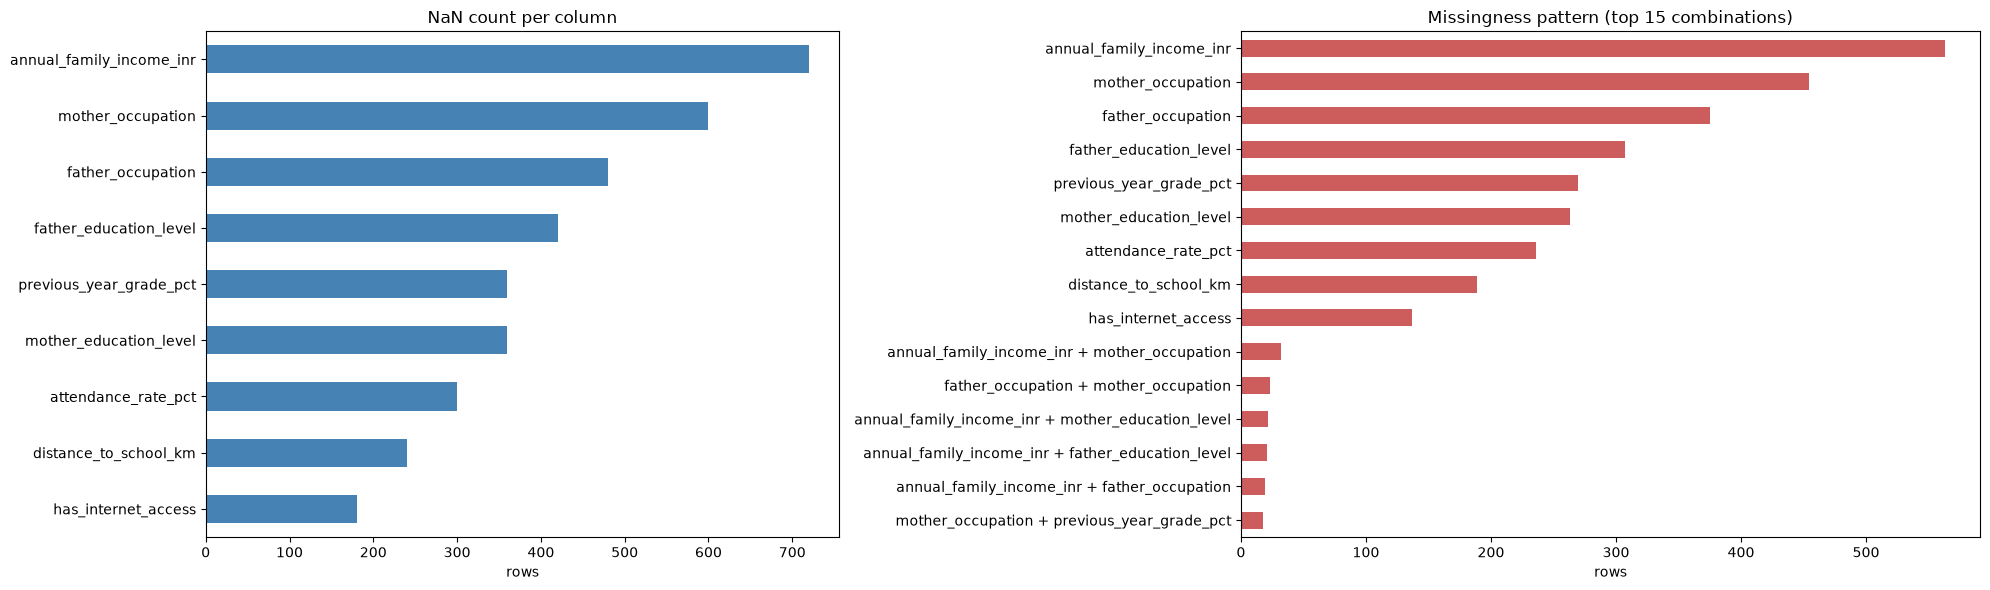

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [69]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

In [70]:
# Check for missing values 
missing_rows = df[df.isna().any(axis=1)]
print("Rows with missing values:")
print(missing_rows) 

# Calculate percentage of missing cells per column 
col_missing_pct = df.isna().mean() * 100

# Filter to only show columns that actually have missing data, sorted highest to lowest
print("\nPercentage of missing values per column:")
print(col_missing_pct[col_missing_pct > 0].sort_values(ascending=False))

# TEMPORARY: drop rows with missing values until a proper imputation strategy is added
rows_before = len(df)
df = df.dropna()
print(f"\n{rows_before} rows -> {len(df)} after dropping rows with missing values")

Rows with missing values:
           academic_year survey_date  age  gender  grade_level  \
student_id                                                       
STU107546      2022-2023      2/5/25   15    Male           10   
STU106506      2022-2023      7/4/25   18    Male           12   
STU103794      2023-2024     20/3/25   16  Female           12   
STU101647      2022-2023     13/3/25   14    Male           10   
STU105006      2021-2022      8/4/25   15    Male            9   
...                  ...         ...  ...     ...          ...   
STU108600      2024-2025      7/3/25   17    Male           11   
STU108332      2024-2025     19/4/25   16  Female           10   
STU106690      2024-2025      6/3/25   13  Female            9   
STU108524      2021-2022      8/4/25   13  Female            9   
STU110137      2023-2024     17/4/25   12  Female            7   

                 school_type residence_type  family_size  num_siblings  \
student_id                               

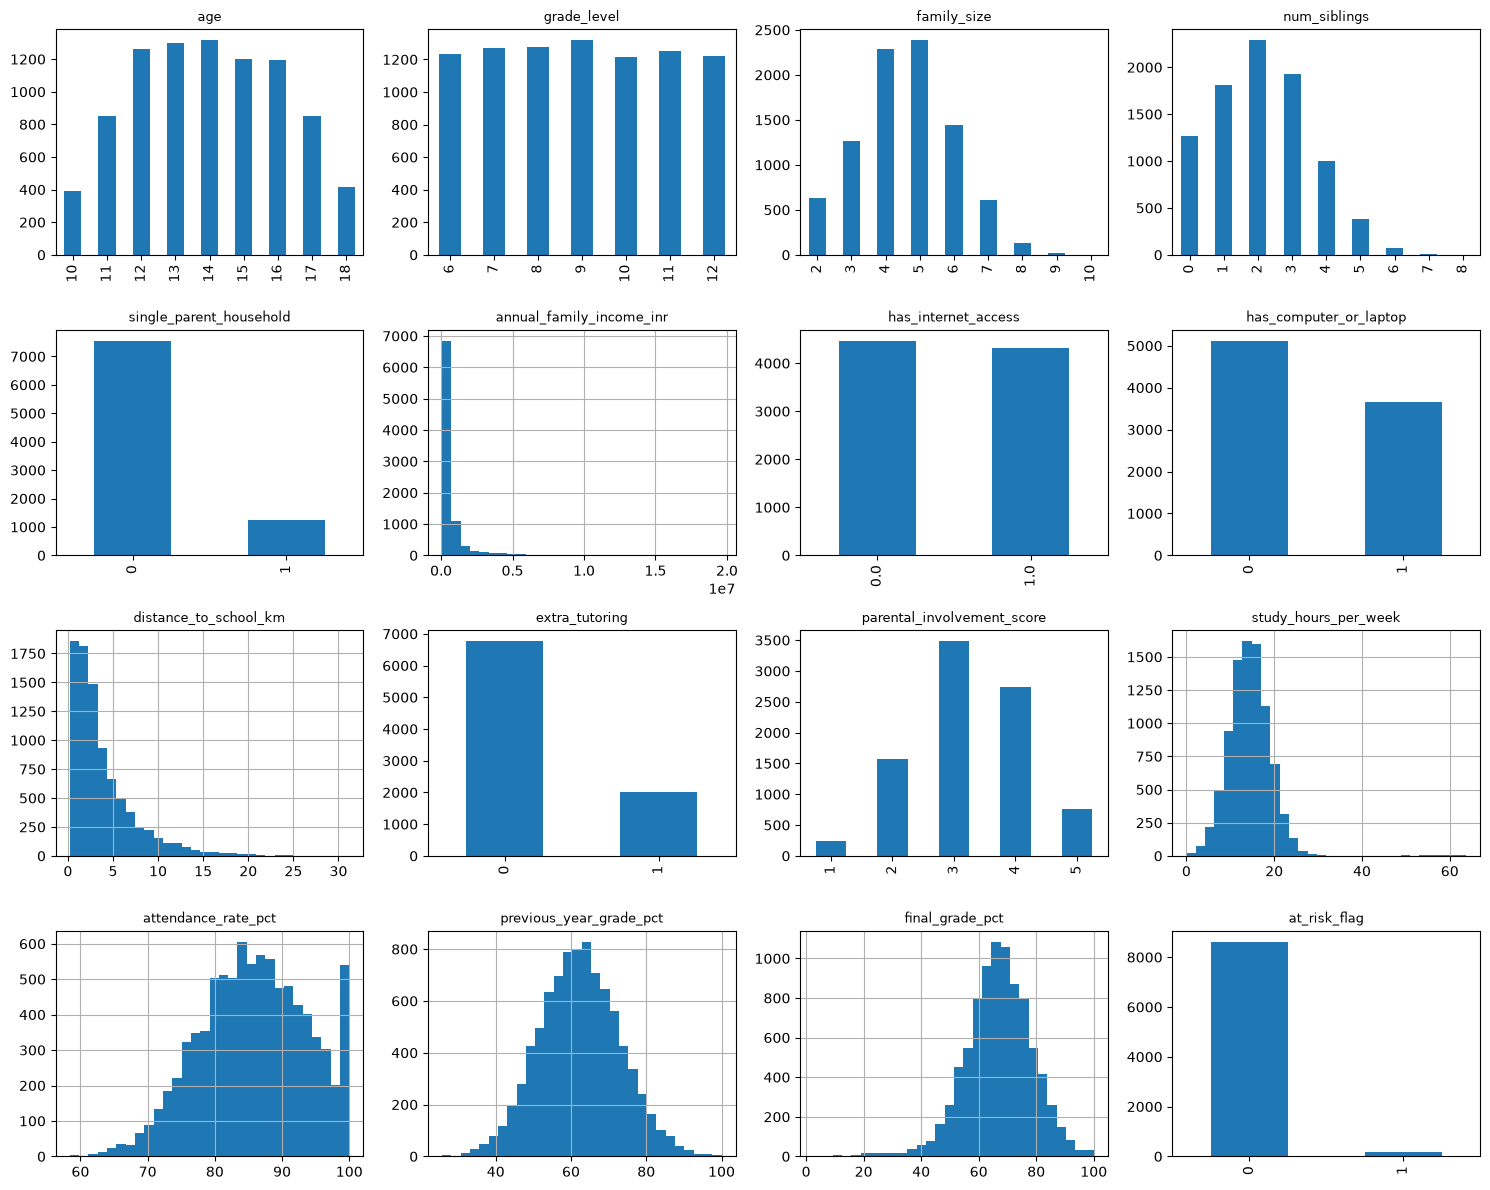

In [71]:
# Visualisation of predictors 

# Columns with only a few integer values get one bar per value
# Default histogram bins cut across the integers and leave gaps
num_cols = df.select_dtypes('number').columns

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax)
    ax.set_title(col, fontsize=9)

plt.tight_layout()
plt.show()

## Skewed income column: annual_family_income_inr

From the histogram above, we can see that the annual_family_income_inr column is very right-skewed. In the data it ranges from about ₹60,000 to ₹19.6 million, a factor of more than 300. Most families sit near the low end and a few earn far more. On the raw scale, the few very rich families stretch the axis. This creates the problems of the ultra-wealthy outliers having too much influence in linear models. 

In such cases, a log transformation is ideal because algorithms like linear regression, logistics regression, K-means clustering and PCA are highly sensitive to extreme values and perform better when features are normally distributed. As the log is a monotonically increasing function, it naturally squashes massive numbers closer together while preserving the exact rank order of data.

In [72]:
# From the histogram above, heavily skewed income, so log-transform 
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
df['log_income'] = np.log(df.pop('annual_family_income_inr'))
print(f"log_income skew: {df['log_income'].skew()}")

annual_family_income_inr skew: 4.780808241327417
log_income skew: 0.4325102438592182


## Schema Setup

Based off the variable histograms above, we can deduce which of the columns are discrete/continuous/categorical and we can form the column schema below. 

In [73]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'log_income'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [74]:
X = df[PREDICTOR_COLS]
print('X:', X.shape)

X: (8785, 24)


## Highly Correlated Predictors 



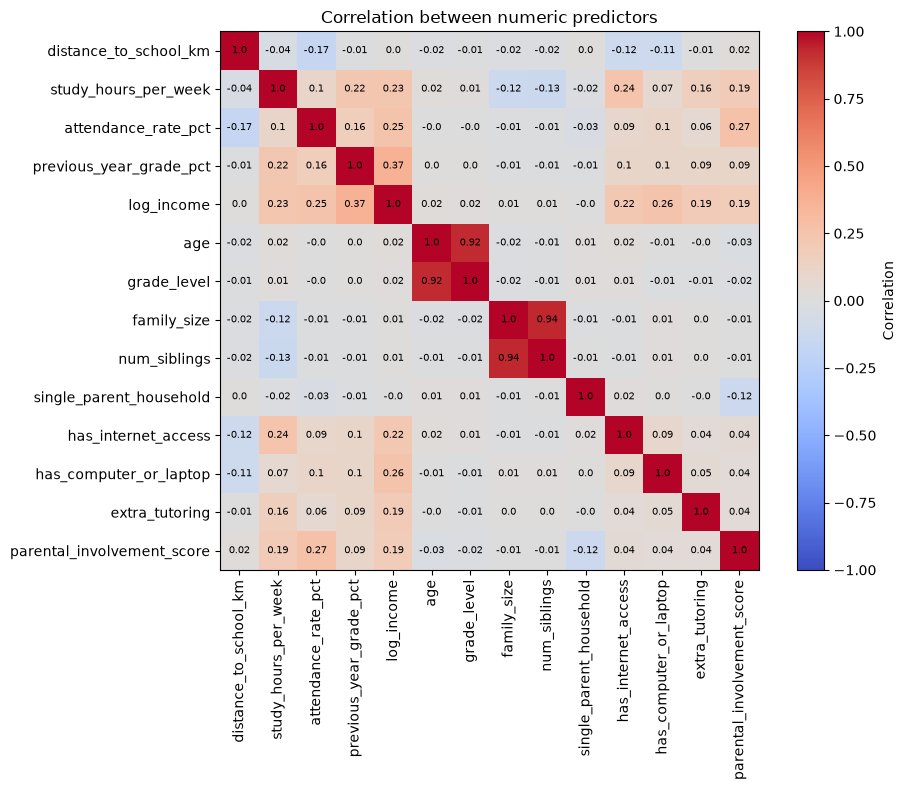

In [75]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Both columns in each pair are almost uncorrelated with `final_grade_pct` (|r| about 0.00 for age/grade level and 0.05 for family size/siblings), so the choice is made on what the variable means rather than on the target. This also avoids using the target before the train/test split.

In [76]:
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (8785, 22)


In [77]:
# Setup helper functions for data preparation so that X-train and X-test can be massaged into a format palatable to each model 

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, RegressorMixin
from pygam import LinearGAM, s, l      # pip install pygam
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from scipy.stats import norm

# Columns with no natural order: one-hot encoded
ONEHOT_COLUMNS = ['gender', 'school_type', 'residence_type', 'academic_year',
                  'father_occupation', 'mother_occupation']

# Columns with a clear order (lowest level first): ordinal encoded
ORDINAL_COLUMNS = {
    'father_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'mother_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'family_income_bracket': ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'scholarship_status': ['No Scholarship', 'Partial', 'Full'],
}

def build_prep(scale):
    # one-hot and ordinal encoders are the same for every family. Only scaling differs
    return ColumnTransformer([
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
        ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
        ('num', StandardScaler() if scale else 'passthrough', NUMERIC_COLS),
    ])

def make_linear_prep():  # OLS, Ridge, Lasso
    return build_prep(scale=True)

def make_gam_prep():     # GAM: splines handle the shape, so no scaling
    return build_prep(scale=False)

class GAMRegressor(BaseEstimator, RegressorMixin):
    # Wrapper so pygam's LinearGAM works inside a Pipeline and GridSearchCV
    # Smooth spline term for each continuous column, linear term for every other column
    def __init__(self, n_splines=10, lam=0.6):
        self.n_splines = n_splines
        self.lam = lam      # smoothing penalty, bigger = smoother curves

    def fit(self, X, y):
        first_continuous = X.shape[1] - len(NUMERIC_COLS)   # one-hot and ordinal columns come first
        last_continuous = first_continuous + len(CONTINUOUS_COLS)
        terms = l(0)
        for j in range(1, X.shape[1]):
            if first_continuous <= j < last_continuous:
                terms = terms + s(j, n_splines=self.n_splines, lam=self.lam)
            else:
                terms = terms + l(j)
        self.gam_ = LinearGAM(terms).fit(X, y)
        return self

    def predict(self, X):
        return self.gam_.predict(X)

def make_knn_prep():     # KNN: distances need scaled columns
    return build_prep(scale=True)

def make_tree_prep():    # decision tree, random forest
    return build_prep(scale=False)

def make_gbt_prep():     # gradient boosting
    return build_prep(scale=False)

def make_svr_prep():     # SVM: RBF kernel uses distances, so scale
    return build_prep(scale=True)

def compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test):
    # Returns (RMSE, MAE, R2, CV RMSE, mean Gaussian log-likelihood) of a fitted model on the test set
    test_predictions = fitted_model.predict(X_test)
    # CV RMSE on the training data: from the grid search if tuned, otherwise 5-fold cross_val_score
    if hasattr(fitted_model, 'best_score_'):
        cv_rmse = -fitted_model.best_score_
    else:
        cv_rmse = -cross_val_score(fitted_model, X_train, Y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
    # Likelihood uses the CV RMSE as the noise sd, so the test set is not used to choose it
    return (root_mean_squared_error(Y_test, test_predictions),
            mean_absolute_error(Y_test, test_predictions),
            r2_score(Y_test, test_predictions),
            cv_rmse,
            norm.logpdf(Y_test, loc=test_predictions, scale=cv_rmse).mean())



# Hyperparameter Tuning: Coarse-to-Fine Search
The main experiment below repeats a full grid search 20 times, so searching a large grid each time would be computationally expensive. To reduce this cost, a coarse-to-fine search is used: a one-off search over a wide, roughly log-spaced grid of values for each model, evaluated with 5-fold cross-validation on the training data only. The best value and its neighbours form a narrower grid, which the main experiment uses for its tuning.

Ridge: best CV RMSE = 9.484
    model__alpha: best = 300, final grid = [100, 300, 1000]
Lasso: best CV RMSE = 9.482
    model__alpha: best = 0.1, final grid = [0.03, 0.1, 0.3]
GAM: best CV RMSE = 9.494
    model__lam: best = 1000, final grid = [100, 1000]  <-- on the edge of the wide grid
k-NN: best CV RMSE = 9.911
    model__n_neighbors: best = 100, final grid = [50, 100, 200]
    model__weights: best = distance, final grid = ['uniform', 'distance']
Decision tree: best CV RMSE = 9.831
    model__max_depth: best = 6, final grid = [4, 6, 8]
    model__min_samples_leaf: best = 100, final grid = [50, 100, 200]
Random forest: best CV RMSE = 9.618
    model__max_features: best = 0.5, final grid = [0.33, 0.5, 0.8]
    model__min_samples_leaf: best = 20, final grid = [10, 20, 40]
GBT: best CV RMSE = 9.541
    model__learning_rate: best = 0.05, final grid = [0.02, 0.05, 0.1]
    model__max_depth: best = 1, final grid = [1, 2]  <-- on the edge of the wide grid
    model__min_samples_leaf: best 

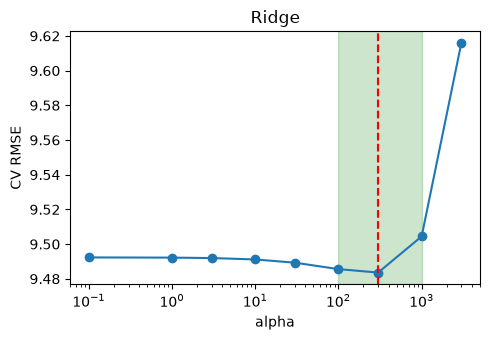

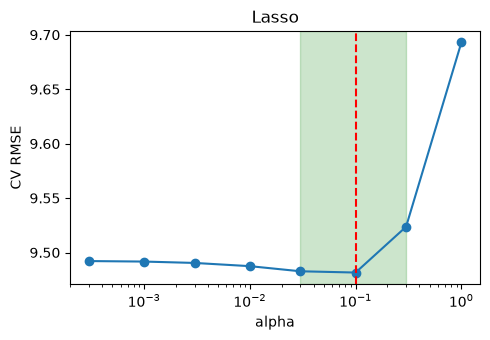

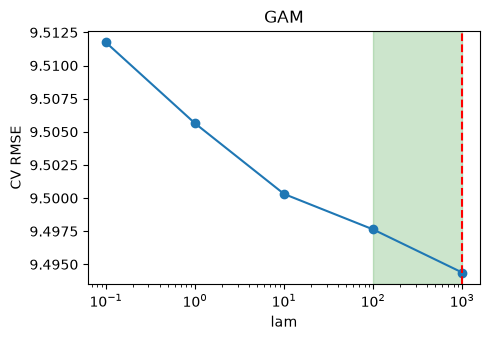

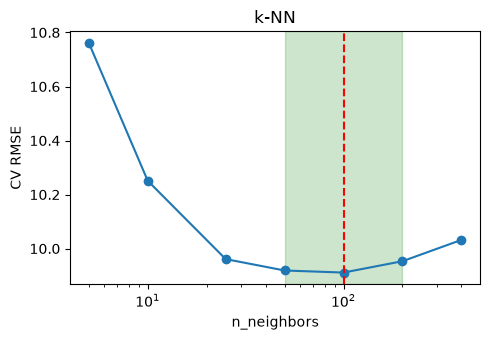

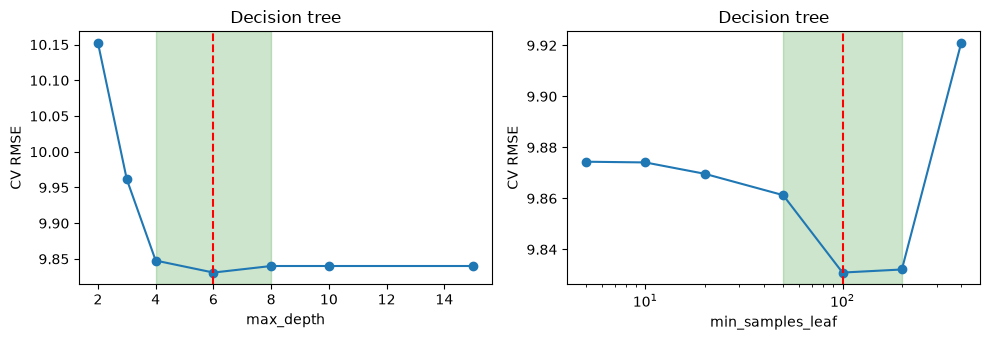

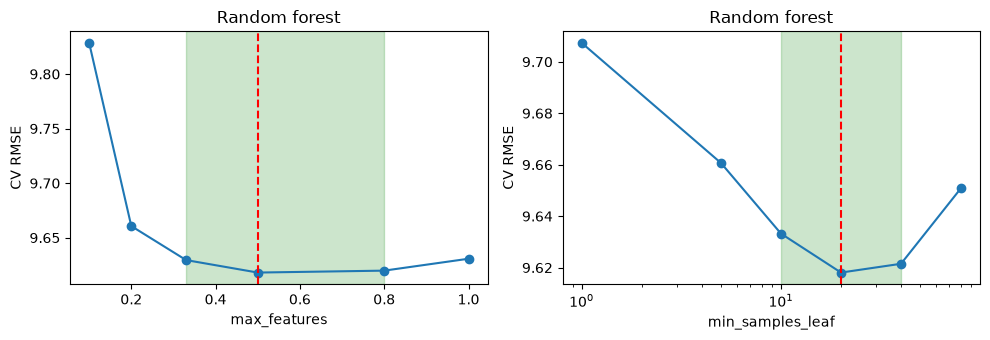

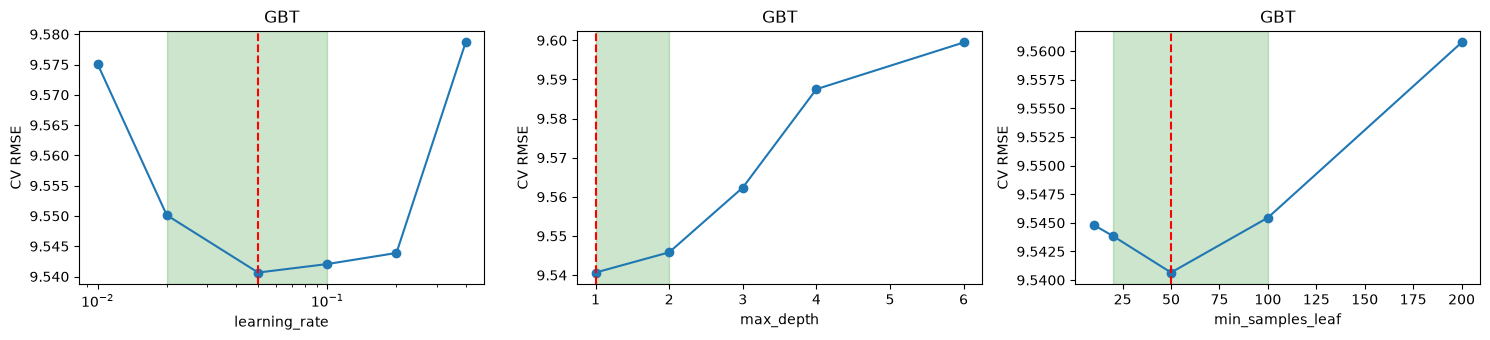

In [78]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
X_pilot, _, Y_pilot, _ = train_test_split(X, Y_regression, test_size=0.15, random_state=0, shuffle=True)
pilot_cv = KFold(n_splits=5, shuffle=True, random_state=0)

# Wide grids
wide_ridge_grid         = {'model__alpha': [0.1, 1, 3, 10, 30, 100, 300, 1000, 3000]}
wide_lasso_grid         = {'model__alpha': [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]}
wide_gam_grid           = {'model__lam': [0.1, 1, 10, 100, 1000]}
wide_knn_grid           = {'model__n_neighbors': [5, 10, 25, 50, 100, 200, 400],
                           'model__weights':     ['uniform', 'distance']}
wide_decision_tree_grid = {'model__max_depth':        [2, 3, 4, 6, 8, 10, 15],
                           'model__min_samples_leaf': [5, 10, 20, 50, 100, 200, 400]}
wide_random_forest_grid = {'model__max_features':     [0.1, 0.2, 0.33, 0.5, 0.8, 1.0],
                           'model__min_samples_leaf': [1, 5, 10, 20, 40, 80]}
wide_gbt_grid           = {'model__learning_rate':    [0.01, 0.02, 0.05, 0.1, 0.2, 0.4],
                           'model__max_depth':        [1, 2, 3, 4, 6],
                           'model__min_samples_leaf': [10, 20, 50, 100, 200]}

# Name: (pipeline, wide grid)
pilot_models = {
    'Ridge':          (Pipeline([('prep', make_linear_prep()), ('model', Ridge())]),                                                              wide_ridge_grid),
    'Lasso':          (Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))]),                                                wide_lasso_grid),
    'GAM':            (Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())]),                                                       wide_gam_grid),
    'k-NN':           (Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor())]),                                                wide_knn_grid),
    'Decision tree':  (Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=0))]),                                wide_decision_tree_grid),
    'Random forest':  (Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=0))]),   wide_random_forest_grid),
    'GBT':            (Pipeline([('prep', make_gbt_prep()),    ('model', HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=0))]), wide_gbt_grid),
}

def narrow(values, best_value):
    # keep the best value and one neighbour on each side
    i = values.index(best_value)
    return values[max(i - 1, 0): i + 2]

pilot_results = {}
best_values   = {}
final_grids   = {}

for name, (pipe, grid) in pilot_models.items():
    search = GridSearchCV(pipe, grid, cv=pilot_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_pilot, Y_pilot)
    pilot_results[name] = pd.DataFrame(search.cv_results_)
    best_values[name]   = search.best_params_
    final_grids[name]   = {}

    print(f'{name}: best CV RMSE = {-search.best_score_:.3f}')
    for param, values in grid.items():
        best = search.best_params_[param]
        if isinstance(values[0], str):      # text options (weights) are kept as they are
            final_grids[name][param] = values
        else:
            final_grids[name][param] = narrow(values, best)
        edge = '  <-- on the edge of the wide grid' if best in (values[0], values[-1]) and not isinstance(best, str) else ''
        print(f'    {param}: best = {best}, final grid = {final_grids[name][param]}{edge}')

# Plot CV RMSE for each numeric hyperparameter (best score over the other hyperparameters)
# red line = best value, green band = range passed to the main script
for name, (pipe, grid) in pilot_models.items():
    params = [p for p in grid if not isinstance(grid[p][0], str)]
    fig, axes = plt.subplots(1, len(params), figsize=(5 * len(params), 3.5), squeeze=False)
    for ax, param in zip(axes[0], params):
        curve = -pilot_results[name].groupby('param_' + param)['mean_test_score'].max()
        ax.plot(curve.index.astype(float), curve.values, marker='o')
        ax.axvspan(min(final_grids[name][param]), max(final_grids[name][param]), color='green', alpha=0.2)
        ax.axvline(best_values[name][param], color='red', linestyle='--')
        if max(grid[param]) / min(grid[param]) > 20:
            ax.set_xscale('log')
        ax.set_xlabel(param.split('__')[-1])
        ax.set_ylabel('CV RMSE')
        ax.set_title(name)
    plt.tight_layout()
    plt.show()

# Pass the final grids on to the main script below
ridge_grid         = final_grids['Ridge']
lasso_grid         = final_grids['Lasso']
gam_grid           = final_grids['GAM']
knn_grid           = final_grids['k-NN']
decision_tree_grid = final_grids['Decision tree']
random_forest_grid = final_grids['Random forest']
gbt_grid           = final_grids['GBT']

In [79]:
# Main Script 

# Imports 
import time

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance

# Store (RMSE, MAE, R2, CV RMSE, log-likelihood) on the test set for each iteration, one tuple per loop 
errors_naive                = []
errors_ols                  = []
errors_ridge                = []
errors_lasso                = []
errors_gam                  = []
errors_k_nearest_neighbors  = []
errors_decision_tree        = []
errors_random_forest        = []
errors_gradient_boosting    = []

# Feature importance collected in every experiment, so the feature selection section can report a mean and spread
importance_records       = []   # one row per (experiment, model): permutation importance of every predictor on that experiment's test set
lasso_selection_records  = []   # one row per experiment: True if the Lasso kept the predictor (any encoded column non-zero)
lasso_coefficient_records = []  # one row per experiment: the tuned Lasso's coefficient for every encoded column

def predictor_of(encoded_name):
    # 'onehot__father_occupation_Unemployed' -> 'father_occupation'
    stripped = encoded_name.split('__', 1)[1]
    return max((p for p in PREDICTOR_COLS if stripped == p or stripped.startswith(p + '_')), key=len)


# CONST HELPERS
TEST_SIZE              = 0.15 # 85/15 split 
NUMBER_OF_EXPERIMENTS  = 20   # Each experiment = new random 85/15 split, tune every model, score on the test set. 20 runs for rigorous statistical difference analysis

# HYPERPARAMETERS: ridge_grid, lasso_grid, gam_grid, knn_grid, decision_tree_grid, random_forest_grid and gbt_grid
# come from the pilot cell above (run it first). Keys use the pipeline step prefix: model__

for experiment in range(NUMBER_OF_EXPERIMENTS): 
    
    # Step 1. 85/15 train/test split: standardized baseline for model comparison across models for this experiment 
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y_regression, test_size=TEST_SIZE, random_state=experiment, shuffle=True)
    experiment_start_time = time.time()
    print('train:', X_train.shape, ' test:', X_test.shape)
    
    # Step 2. Model-specific pre-processing (one-hot/ordinal encoding, standardization etc.)
    # Each pipeline chains a preprocessor with a final model, so it can be fitted and used to predict directly
    naive_pipe               = Pipeline([('prep', make_linear_prep()), ('model', DummyRegressor(strategy='mean'))])                                                             # Linear: naive mean
    ols_pipe                 = Pipeline([('prep', make_linear_prep()), ('model', LinearRegression())])                                                                          # Linear: OLS
    ridge_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Ridge())])                                                                                     # Linear: Ridge
    lasso_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))])                                                                       # Linear: Lasso
    gam_pipe                 = Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())])                                                                              # GAM
    k_nearest_neighbors_pipe = Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor())])                                                                       # k-NN
    decision_tree_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=experiment))])                                              # Decision tree
    random_forest_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=experiment, n_jobs=-1))])                 # Random forest
    gradient_boosting_pipe   = Pipeline([('prep', make_gbt_prep()),    ('model', HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=experiment))])   # Boosting / GBT

    # Step 3. GridSearchCV - K-folds on 85% training data with aim of finding the best hyperparameters.
    cv = KFold(n_splits=10, shuffle=True, random_state=experiment)
    # Random forest is the slowest model, so it uses 5 folds instead of 10
    random_forest_cv = KFold(n_splits=5, shuffle=True, random_state=experiment)
    scoring = 'neg_root_mean_squared_error'

    # Define the grid searches
    ridge_search                = GridSearchCV(ridge_pipe, ridge_grid, cv=cv, scoring=scoring)
    lasso_search                = GridSearchCV(lasso_pipe, lasso_grid, cv=cv, scoring=scoring)
    gam_search                  = GridSearchCV(gam_pipe, gam_grid, cv=cv, scoring=scoring, n_jobs=-1)
    k_nearest_neighbors_search  = GridSearchCV(k_nearest_neighbors_pipe, knn_grid, cv=cv, scoring=scoring, n_jobs=-1)
    decision_tree_search        = GridSearchCV(decision_tree_pipe, decision_tree_grid, cv=cv, scoring=scoring, n_jobs=-1)
    random_forest_search        = GridSearchCV(random_forest_pipe, random_forest_grid, cv=random_forest_cv, scoring=scoring)
    gradient_boosting_search    = GridSearchCV(gradient_boosting_pipe, gbt_grid, cv=cv, scoring=scoring)

    # Fit everything on the 85% training data
    naive_pipe.fit(X_train, Y_train)      # predicts the training mean, no hyperparameters
    ols_pipe.fit(X_train, Y_train)        # OLS has no hyperparameters
    ridge_search.fit(X_train, Y_train)
    lasso_search.fit(X_train, Y_train)
    gam_search.fit(X_train, Y_train)
    k_nearest_neighbors_search.fit(X_train, Y_train)
    decision_tree_search.fit(X_train, Y_train)
    random_forest_search.fit(X_train, Y_train)
    gradient_boosting_search.fit(X_train, Y_train)
    
    # Step 4. Evaluate best chosen hyperparameter for each model and validate using 15% testing data set 
    # GridSearchCV objects predict with their best refitted pipeline
    fitted_models = [
        (naive_pipe, errors_naive),
        (ols_pipe, errors_ols),
        (ridge_search, errors_ridge),
        (lasso_search, errors_lasso),
        (gam_search, errors_gam),
        (k_nearest_neighbors_search, errors_k_nearest_neighbors),
        (decision_tree_search, errors_decision_tree),
        (random_forest_search, errors_random_forest),
        (gradient_boosting_search, errors_gradient_boosting)
    ]
    
    # Step 5. Record performance metrics (RMSE, MAE, R2, CV RMSE, log-likelihood) for this iteration 
    for fitted_model, error_list in fitted_models:
        error_list.append(compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test))

    # Step 5b. Feature importance of the tuned models on this experiment's test set
    for importance_name, importance_search in [('Lasso', lasso_search), ('DT', decision_tree_search),
                                               ('RF', random_forest_search), ('GBT', gradient_boosting_search)]:
        result = permutation_importance(importance_search.best_estimator_, X_test, Y_test,
                                        scoring='neg_root_mean_squared_error', n_repeats=5, random_state=experiment)
        importance_records.append({'experiment': experiment, 'model': importance_name,
                                   **dict(zip(PREDICTOR_COLS, result.importances_mean))})

    # Predictors the tuned Lasso kept in this experiment
    lasso_best = lasso_search.best_estimator_
    lasso_coefficients = pd.Series(lasso_best.named_steps['model'].coef_, index=lasso_best.named_steps['prep'].get_feature_names_out())
    kept_predictors = {predictor_of(name) for name in lasso_coefficients.index[lasso_coefficients != 0]}
    lasso_selection_records.append({'experiment': experiment, **{p: p in kept_predictors for p in PREDICTOR_COLS}})
    lasso_coefficient_records.append({'experiment': experiment, **lasso_coefficients.to_dict()})

    print(f'experiment {experiment + 1}/{NUMBER_OF_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')
    
    # Step 6. Create some visualisations if necessary. 
    
    


train: (7467, 22)  test: (1318, 22)
experiment 1/20 done in 41s
train: (7467, 22)  test: (1318, 22)
experiment 2/20 done in 42s
train: (7467, 22)  test: (1318, 22)
experiment 3/20 done in 44s
train: (7467, 22)  test: (1318, 22)
experiment 4/20 done in 43s
train: (7467, 22)  test: (1318, 22)
experiment 5/20 done in 46s
train: (7467, 22)  test: (1318, 22)
experiment 6/20 done in 40s
train: (7467, 22)  test: (1318, 22)
experiment 7/20 done in 42s
train: (7467, 22)  test: (1318, 22)
experiment 8/20 done in 47s
train: (7467, 22)  test: (1318, 22)
experiment 9/20 done in 43s
train: (7467, 22)  test: (1318, 22)
experiment 10/20 done in 42s
train: (7467, 22)  test: (1318, 22)
experiment 11/20 done in 43s
train: (7467, 22)  test: (1318, 22)
experiment 12/20 done in 41s
train: (7467, 22)  test: (1318, 22)
experiment 13/20 done in 46s
train: (7467, 22)  test: (1318, 22)
experiment 14/20 done in 41s
train: (7467, 22)  test: (1318, 22)
experiment 15/20 done in 41s
train: (7467, 22)  test: (1318, 22

## Model Performance Metrics 

The following metrics apply to all nine regression models:

- **RMSE**: typical error size, penalises large errors (also the tuning criterion)
- **MAE**: average absolute error, less sensitive to outliers
- **CV RMSE**: RMSE from the k-fold tuning on the 85% training data (`best_score_`; 5-fold `cross_val_score` for naive and OLS). Compared with the test RMSE, it shows how well tuning predicts test performance
- **R2**: share of variance explained versus predicting the mean (the naive model is about 0)
- **Gaussian test log-likelihood (MLE)**: mean of log N(y; prediction, sigma^2) over the test set, higher is better. Sigma is the CV RMSE on the training data. With Gaussian errors this is a decreasing function of MSE, so it ranks models like RMSE unless the sigmas differ

AIC/BIC are left out because comparing them requires suitable likelihoods and effective parameter counts for each model.



## Visualisation: Box plots and confidence intervals

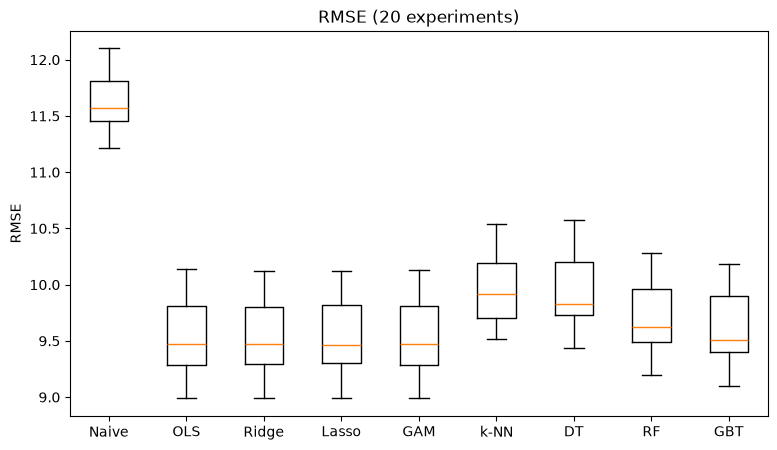

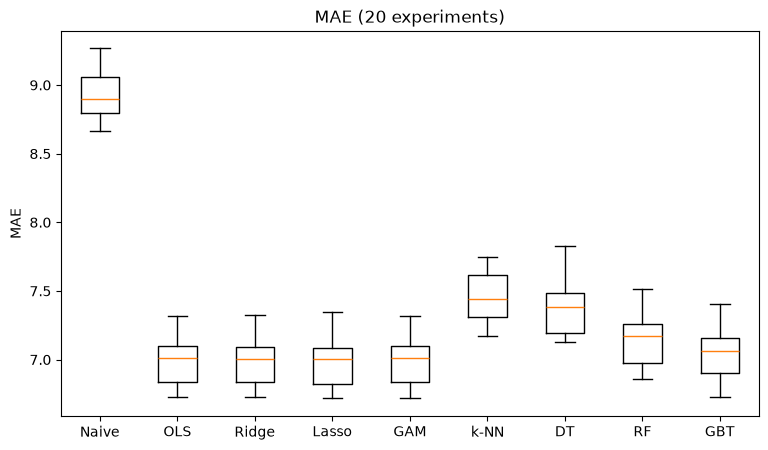

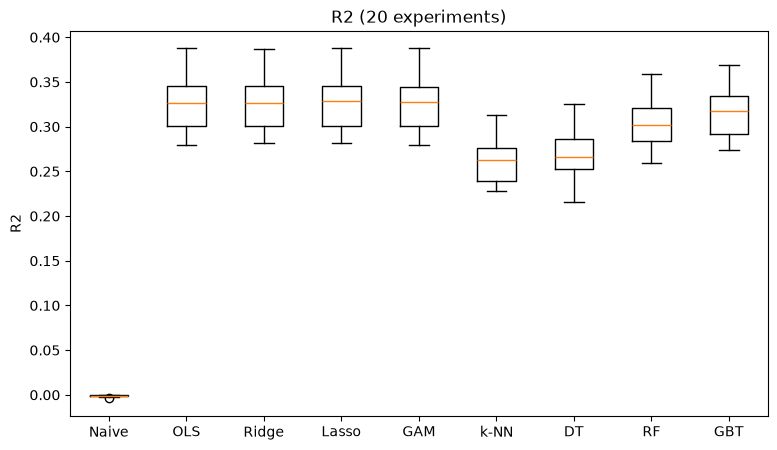

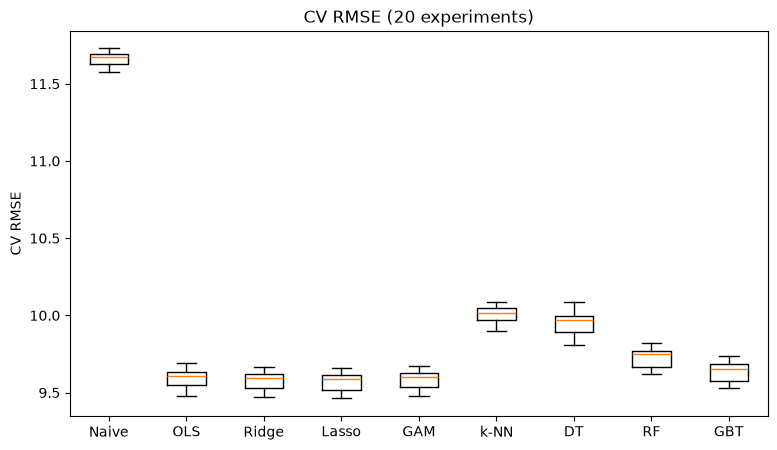

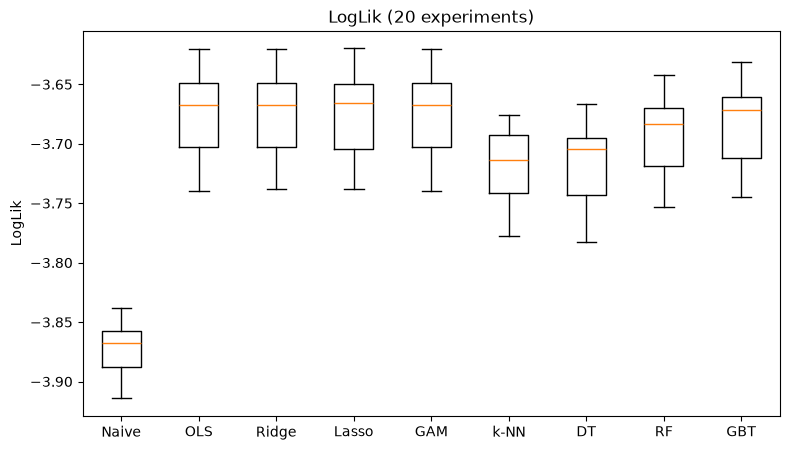

In [80]:
names = ['Naive', 'OLS', 'Ridge', 'Lasso', 'GAM', 'k-NN', 'DT', 'RF', 'GBT']
model_error_lists = [errors_naive, errors_ols, errors_ridge, errors_lasso, errors_gam,
                     errors_k_nearest_neighbors, errors_decision_tree, errors_random_forest, errors_gradient_boosting]

# each loop stores (RMSE, MAE, R2, CV RMSE, LogLik), so column 0 to 4 is one measure
for col, metric in enumerate(['RMSE', 'MAE', 'R2', 'CV RMSE', 'LogLik']):
    plt.figure(figsize=(9, 5))
    plt.boxplot([np.array(e)[:, col] for e in model_error_lists])
    plt.xticks(range(1, len(names) + 1), names)
    plt.ylabel(metric)
    plt.title(f'{metric} ({NUMBER_OF_EXPERIMENTS} experiments)')
    plt.show()


## TODO: Paired differences and t-tests (AI Slop: Needs rewrite)
 
All models share the same split in each experiment, so we compare them on paired differences. Test sets overlap across experiments, so a plain paired t-test is too optimistic. We use the Nadeau-Bengio corrected variance, se = sqrt((1/N + n_test/n_train) * var(diff)), with N-1 degrees of freedom. For each metric, each model is compared with the best model on that metric, and p-values are Holm-adjusted for the eight comparisons. Because the best model is selected on these same test results, interpret the p-values as exploratory.

In [81]:
from scipy.stats import t as t_distribution

def corrected_paired_ttest(scores_a, scores_b, test_fraction=TEST_SIZE):
    # Nadeau-Bengio corrected paired t-test on per-experiment scores, returns (mean diff, t, p)
    diff = np.array(scores_a) - np.array(scores_b)
    n = len(diff)
    se = np.sqrt((1 / n + test_fraction / (1 - test_fraction)) * diff.var(ddof=1))
    t_stat = diff.mean() / se
    return diff.mean(), t_stat, 2 * t_distribution.sf(abs(t_stat), df=n - 1)

def holm_adjust(p_values):
    # Holm step-down adjustment of a list of p-values
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values))
    running_max = 0
    for rank, idx in enumerate(order):
        running_max = max(running_max, (len(p_values) - rank) * p_values[idx])
        adjusted[idx] = min(1, running_max)
    return adjusted

# RMSE: lower is better (column 0). Log-likelihood: higher is better (column 4)
for col, metric in [(0, 'RMSE'), (4, 'LogLik')]:
    scores = [np.array(e)[:, col] for e in model_error_lists]
    best = np.argmin([s.mean() for s in scores]) if metric == 'RMSE' else np.argmax([s.mean() for s in scores])
    others = [i for i in range(len(names)) if i != best]
    results = [corrected_paired_ttest(scores[i], scores[best]) for i in others]
    holm_p = holm_adjust([r[2] for r in results])
    table = pd.DataFrame({'model': [names[i] for i in others],
                          f'mean {metric} diff vs best': [r[0] for r in results],
                          't': [r[1] for r in results],
                          'p': [r[2] for r in results],
                          'Holm p': holm_p})
    print(f'\n{metric}: best model = {names[best]}')
    print(table.round(4).to_string(index=False))



RMSE: best model = Lasso
model  mean RMSE diff vs best       t      p  Holm p
Naive                  2.1067 22.7898 0.0000  0.0000
  OLS                  0.0047  0.6437 0.5275  1.0000
Ridge                  0.0029  0.5355 0.5985  1.0000
  GAM                  0.0069  0.9144 0.3720  1.0000
 k-NN                  0.4613 13.7653 0.0000  0.0000
   DT                  0.3983 10.8206 0.0000  0.0000
   RF                  0.1737  7.8528 0.0000  0.0000
  GBT                  0.0742  5.0287 0.0001  0.0003

LogLik: best model = Lasso
model  mean LogLik diff vs best        t      p  Holm p
Naive                   -0.1990 -19.0841 0.0000  0.0000
  OLS                   -0.0005  -0.6486 0.5244  1.0000
Ridge                   -0.0003  -0.4912 0.6289  1.0000
  GAM                   -0.0007  -0.8916 0.3838  1.0000
 k-NN                   -0.0470 -12.5986 0.0000  0.0000
   DT                   -0.0408 -10.0579 0.0000  0.0000
   RF                   -0.0179  -7.3937 0.0000  0.0000
  GBT                

# TODO: Classification (AI slop)

In [ ]:
# Classification: predict grade_class using the same predictors as regression
import time
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, confusion_matrix, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


K_FOLDS       = 5
GRADE_CLASSES = ['A', 'B', 'C', 'D', 'F']

classification_results = []
classification_names = ['Naive', 'DT', 'Bagging', 'RF', 'k-NN', 'SVM']
classification_confusion_matrices = {name: [] for name in classification_names}
macro_f1_scorer = make_scorer(f1_score, average='macro', zero_division=0)

for experiment in range(NUMBER_OF_EXPERIMENTS):
    # Step 1. Stratified train/test split shared by all classifiers
    X_train_class, X_test_class, Y_train_class, Y_test_class = train_test_split(
        X, Y_classification, test_size=TEST_SIZE,
        stratify=Y_classification, random_state=experiment
    )
    experiment_start_time = time.time()

    # Step 2. Set up model-specific preprocessing and classifiers
    naive_class_pipe               = Pipeline([('prep', make_tree_prep()), ('model', DummyClassifier(strategy='most_frequent'))])
    decision_tree_class_pipe       = Pipeline([('prep', make_tree_prep()), ('model', DecisionTreeClassifier(random_state=experiment))])
    bagging_class_pipe             = Pipeline([('prep', make_tree_prep()), ('model', BaggingClassifier(n_estimators=50, random_state=experiment))])
    random_forest_class_pipe       = Pipeline([('prep', make_tree_prep()), ('model', RandomForestClassifier(n_estimators=100, random_state=experiment))])
    k_nearest_neighbors_class_pipe = Pipeline([('prep', make_knn_prep()),  ('model', KNeighborsClassifier())])
    svm_class_pipe                 = Pipeline([('prep', make_svr_prep()),  ('model', SVC(kernel='rbf'))])

    # Step 3. Tune and fit using stratified cross-validation on the training set
    classification_cv = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=experiment)
    classification_models = {
        'Naive':   (naive_class_pipe,               {}),
        'DT':      (decision_tree_class_pipe,       {'model__min_samples_leaf': [10, 30]}),
        'Bagging': (bagging_class_pipe,             {'model__max_samples': [0.7, 1.0]}),
        'RF':      (random_forest_class_pipe,       {'model__max_features': [0.5, 1.0]}),
        'k-NN':    (k_nearest_neighbors_class_pipe, {'model__n_neighbors': [15, 45], 'model__weights': ['uniform', 'distance']}),
        'SVM':     (svm_class_pipe,                 {'model__C': [0.1, 1.0, 10.0]}),
    }

    classification_searches = {}
    for name, (pipeline, grid) in classification_models.items():
        search = GridSearchCV(pipeline, grid, cv=classification_cv, scoring=macro_f1_scorer, error_score='raise')
        search.fit(X_train_class, Y_train_class)
        classification_searches[name] = search

    # Steps 4 and 5. Predict on the test set and record classification metrics
    for name, search in classification_searches.items():
        predictions = search.predict(X_test_class)
        class_recall = recall_score(Y_test_class, predictions, labels=GRADE_CLASSES, average=None, zero_division=0)
        classification_confusion_matrices[name].append(confusion_matrix(Y_test_class, predictions, labels=GRADE_CLASSES))
        classification_results.append({
            'experiment': experiment + 1, 'model': name, 'CV macro F1': search.best_score_,
            'train size': len(X_train_class), 'test size': len(X_test_class),
            'accuracy': accuracy_score(Y_test_class, predictions),
            'balanced accuracy': balanced_accuracy_score(Y_test_class, predictions),
            'macro F1': f1_score(Y_test_class, predictions, labels=GRADE_CLASSES, average='macro', zero_division=0),
            'class recall': dict(zip(GRADE_CLASSES, class_recall)), 'best parameters': search.best_params_,
        })
    print(f'experiment {experiment + 1}/{NUMBER_OF_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')

# Summarise results across experiments
classification_results = pd.DataFrame(classification_results)
classification_summary = classification_results.groupby('model')[['CV macro F1', 'accuracy', 'balanced accuracy', 'macro F1']].agg(['mean', 'std']).reindex(classification_names)
classification_class_recall = pd.DataFrame(classification_results['class recall'].tolist(), index=classification_results.index)
classification_mean_recall = classification_class_recall.groupby(classification_results['model']).mean().reindex(classification_names)


## Classification performance across experiments (AI Slop)

Boxplots show variation across repeated test splits; they are not confidence intervals. The second plot shows paired macro-F1 differences against the Naive baseline with approximate 95% intervals. Its Nadeau-Bengio correction accounts approximately for overlapping splits, but the intervals are exploratory, not exact or simultaneous, especially for rare grades.

In [ ]:
from scipy.stats import t as t_distribution
from warnings import warn

# One row per experiment, with each model evaluated on the same split
classification_scores = classification_results.pivot(index='experiment', columns='model', values='macro F1')[classification_names]

# Boxplots show test-set variation, with higher scores being better
for metric, label in [('macro F1', 'Macro-F1'), ('balanced accuracy', 'Balanced accuracy'), ('accuracy', 'Accuracy')]:
    scores = classification_results.pivot(index='experiment', columns='model', values=metric)[classification_names]
    plt.figure(figsize=(9, 5))
    plt.boxplot([scores[name].to_numpy() for name in classification_names])
    plt.xticks(range(1, len(classification_names) + 1), classification_names)
    plt.ylim(0, 1)
    plt.ylabel(label)
    plt.title(f'{label} on the test set ({len(scores)} experiments)')
    plt.tight_layout()
    plt.show()

# Approximate corrected intervals for paired macro-F1 differences versus Naive
differences = classification_scores.drop(columns='Naive').sub(classification_scores['Naive'], axis=0)
number_of_splits = len(differences)
classification_intervals = None
if number_of_splits < 2:
    warn('At least two experiments are needed for confidence intervals; interval plot skipped.')
else:
    sizes = classification_results.groupby('experiment')[['train size', 'test size']].first().loc[classification_scores.index]
    test_train_ratio = (sizes['test size'] / sizes['train size']).mean()
    standard_error = np.sqrt((1 / number_of_splits + test_train_ratio) * differences.var(ddof=1))
    margin = t_distribution.ppf(0.975, df=number_of_splits - 1) * standard_error
    classification_intervals = pd.DataFrame({'mean difference': differences.mean(), 'lower 95%': differences.mean() - margin,
                                             'upper 95%': differences.mean() + margin})

    plt.figure(figsize=(8, 4))
    plt.errorbar(classification_intervals['mean difference'], classification_intervals.index, xerr=margin, fmt='o', capsize=4)
    plt.axvline(0, color='black', linestyle='--')
    plt.xlabel('Test macro-F1 difference versus Naive (higher is better)')
    plt.title('Paired differences: approximate corrected 95% intervals')
    plt.tight_layout()
    plt.show()


# Unsupervised Learning: K-means and PCA (AI Slop)

Feature Exploration 
Dimensionality Reduction (PCA) / Clustering (K-means)

The setup below uses the shared predictors only. Numeric variables are standardized, ordinal variables keep their existing order, and all one-hot levels are retained so categories have equal pairwise distances. The encoded categorical variables are not standardized, so their weights differ from those of the numeric variables. This is exploratory preprocessing fitted on all available rows; predictive use would require fitting it on training data only.

PCA summarises variation in the prepared predictors. The first two components may not capture all of the structure in the data, and large loadings do not necessarily imply predictive importance.

K-means is fitted on all prepared predictors, not just the first two principal components. Silhouette scores use the same random sample of up to 2,000 students for each candidate. The highest score gives a provisional choice of cluster count; check the scores, sizes, stability and profiles before interpreting it. The seed comparison checks sensitivity to initialization, not sampling or preprocessing choices.

The PCA plots show the same two-dimensional projection coloured by cluster and by grade class. Clusters are fitted in the full predictor space, and grades are added only afterwards. Differences between groups are descriptive associations, not causal effects or independent validation; the clusters may change with the choice of preprocessing and distance weights.


In [ ]:
# Setup for PCA and K-means
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

UNSUPERVISED_RANDOM_STATE = 0
CLUSTER_COUNTS            = range(2, 9)

# Keep all one-hot levels for distances; scale numeric columns only
unsupervised_prep = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
    ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
    ('numeric', StandardScaler(), NUMERIC_COLS),
])

unsupervised_values = unsupervised_prep.fit_transform(X)
X_unsupervised = pd.DataFrame(
    unsupervised_values,
    index=X.index,
    columns=unsupervised_prep.get_feature_names_out()
)

# Define PCA and candidate K-means models
pca_model = PCA()
kmeans_models = {
    count: KMeans(n_clusters=count, n_init=10, random_state=UNSUPERVISED_RANDOM_STATE)
    for count in CLUSTER_COUNTS
}

# Fit PCA and inspect explained variance and loadings
from IPython.display import display

pca_scores = pca_model.fit_transform(X_unsupervised)
explained_variance = pca_model.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components_for_80_percent = np.searchsorted(cumulative_variance, 0.80) + 1

print(f'Components needed for 80% of variance: {components_for_80_percent}')

pca_loadings = pd.DataFrame(
    pca_model.components_[:2].T,
    index=X_unsupervised.columns,
    columns=['PC1', 'PC2']
)
for component in pca_loadings.columns:
    largest_loadings = pca_loadings[component].abs().nlargest(5).index
    print(f'Largest {component} loadings:')
    display(pca_loadings.loc[largest_loadings, [component]].round(3))

# Compare cluster counts using inertia and silhouette score
from sklearn.metrics import adjusted_rand_score, silhouette_score

cluster_results = []
for count, model in kmeans_models.items():
    labels = model.fit_predict(X_unsupervised)
    cluster_results.append({
        'clusters':   count,
        'inertia':    model.inertia_,
        'silhouette': silhouette_score(
            X_unsupervised, labels, sample_size=min(2000, len(X_unsupervised)),
            random_state=UNSUPERVISED_RANDOM_STATE
        ),
    })

cluster_results = pd.DataFrame(cluster_results).set_index('clusters')
display(cluster_results.round(3))

selected_cluster_count = cluster_results['silhouette'].idxmax()
selected_kmeans = kmeans_models[selected_cluster_count]
cluster_labels = pd.Series(selected_kmeans.labels_ + 1, index=X.index, name='cluster')
print(f'Provisional cluster count: {selected_cluster_count}')

# Compare the selected solution with other random initializations
seed_stability = []
for seed in [1, 2, 3]:
    alternative_model = KMeans(n_clusters=selected_cluster_count, n_init=10, random_state=seed)
    alternative_labels = alternative_model.fit_predict(X_unsupervised)
    seed_stability.append({
        'random_state': seed,
        'adjusted_rand_score': adjusted_rand_score(selected_kmeans.labels_, alternative_labels)
    })
print('Agreement with the selected solution across random seeds:')
display(pd.DataFrame(seed_stability).set_index('random_state').round(3))

# Summarise predictors and grades after assigning clusters
profile_columns = [
    'study_hours_per_week', 'attendance_rate_pct',
    'previous_year_grade_pct', 'log_income'
]
cluster_data = X[profile_columns].copy()
cluster_data['cluster'] = cluster_labels
cluster_data['final_grade_pct'] = Y_regression
cluster_data['grade_class'] = Y_classification

cluster_profile = cluster_data.groupby('cluster')[profile_columns + ['final_grade_pct']].mean()
cluster_profile.insert(0, 'students', cluster_labels.value_counts().sort_index())
overall_profile = pd.DataFrame(
    [[len(cluster_data)] + cluster_data[profile_columns + ['final_grade_pct']].mean().tolist()],
    index=['Overall'], columns=cluster_profile.columns
)
print('Cluster means and overall means:')
display(pd.concat([cluster_profile, overall_profile]).round(2))

grade_distribution = pd.crosstab(cluster_labels, Y_classification, normalize='index')
print('Grade class distribution within each cluster:')
display((100 * grade_distribution).round(1))
print('School type distribution within each cluster (%):')
display((100 * pd.crosstab(cluster_labels, X['school_type'], normalize='index')).round(1))


Components needed for 80% of variance: 14
Largest PC1 loadings:


,PC1
ordinal__mother_education_level,0.531
ordinal__father_education_level,0.524
ordinal__family_income_bracket,0.432
numeric__log_income,0.357
numeric__previous_year_grade_pct,0.229


Largest PC2 loadings:


,PC2
numeric__attendance_rate_pct,0.375
ordinal__father_education_level,-0.369
numeric__study_hours_per_week,0.368
ordinal__mother_education_level,-0.321
numeric__has_internet_access,0.311


,inertia,silhouette
clusters,,
2,167373.445,0.139
3,159692.057,0.073
4,154394.917,0.076
5,149855.568,0.072
6,146644.203,0.070
7,143806.625,0.066
8,141406.608,0.055


Provisional cluster count: 2
Agreement with the selected solution across random seeds:


... (3 outputs left out)

Grade class distribution within each cluster:


grade_class,A,B,C,D,F
cluster,,,,,
1,3.9,35.9,50.4,8.3,1.6
2,0.3,11.8,52.5,33.5,2.0


School type distribution within each cluster (%):


school_type,Government,Government-Aided,Private-Unaided
cluster,,,
1,44.3,20.0,35.7
2,45.8,19.4,34.7


## Unsupervised Learning: Visualisation

In [ ]:
# PCA explained variance
component_numbers = np.arange(1, len(explained_variance) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, explained_variance)
axes[0].set(title='PCA explained variance', xlabel='Principal component', ylabel='Variance explained')
axes[1].plot(component_numbers, cumulative_variance, marker='o', markersize=3)
axes[1].axhline(0.80, color='grey', linestyle='--', label='80%')
axes[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='Cumulative variance')
axes[1].legend()
plt.tight_layout()
plt.show()

# Largest signed loadings for the first two principal components
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, component in zip(axes, ['PC1', 'PC2']):
    largest_features = pca_loadings[component].abs().nlargest(5).index
    loadings = pca_loadings.loc[largest_features, component].sort_values()
    ax.barh(loadings.index, loadings.values)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(title=f'{component}: largest loadings', xlabel='Loading')
plt.tight_layout()
plt.show()

# K-means diagnostics
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_results.index, cluster_results['inertia'], marker='o')
axes[0].set(title='K-means inertia', xlabel='Number of clusters', ylabel='Inertia')
axes[1].plot(cluster_results.index, cluster_results['silhouette'], marker='o')
axes[1].set(title='K-means silhouette score', xlabel='Number of clusters', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

# Compare clusters and grade classes on the same PCA projection
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for cluster in sorted(cluster_labels.unique()):
    in_cluster = cluster_labels.to_numpy() == cluster
    axes[0].scatter(pca_scores[in_cluster, 0], pca_scores[in_cluster, 1],
                    s=10, alpha=0.35, label=f'Cluster {cluster}')

grade_classes = Y_classification.reindex(X_unsupervised.index)
for grade in grade_classes.value_counts().index:
    in_grade = grade_classes.to_numpy() == grade
    axes[1].scatter(pca_scores[in_grade, 0], pca_scores[in_grade, 1],
                    s=10, alpha=0.35, label=f'Grade {grade}')

for ax in axes:
    ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%} variance)')
    ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%} variance)')
    ax.legend()
axes[0].set_title('Coloured by cluster')
axes[1].set_title('Coloured by grade class')
plt.tight_layout()
plt.show()

# Grade class distribution within each cluster
grade_distribution.plot.bar(stacked=True, figsize=(8, 5), colormap='viridis')
plt.title('Grade class distribution by cluster')
plt.xlabel('Cluster')
plt.ylabel('Proportion of students')
plt.legend(title='Grade class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


# Feature Selection (AI Slop)

This section uses Lasso and tree-based models to explore which predictors are useful for predicting `final_grade_pct`. Lasso can shrink coefficients to zero. For the tree models, we measure how much the holdout RMSE increases when each predictor is shuffled. These results are for exploration and are separate from the main model comparison.


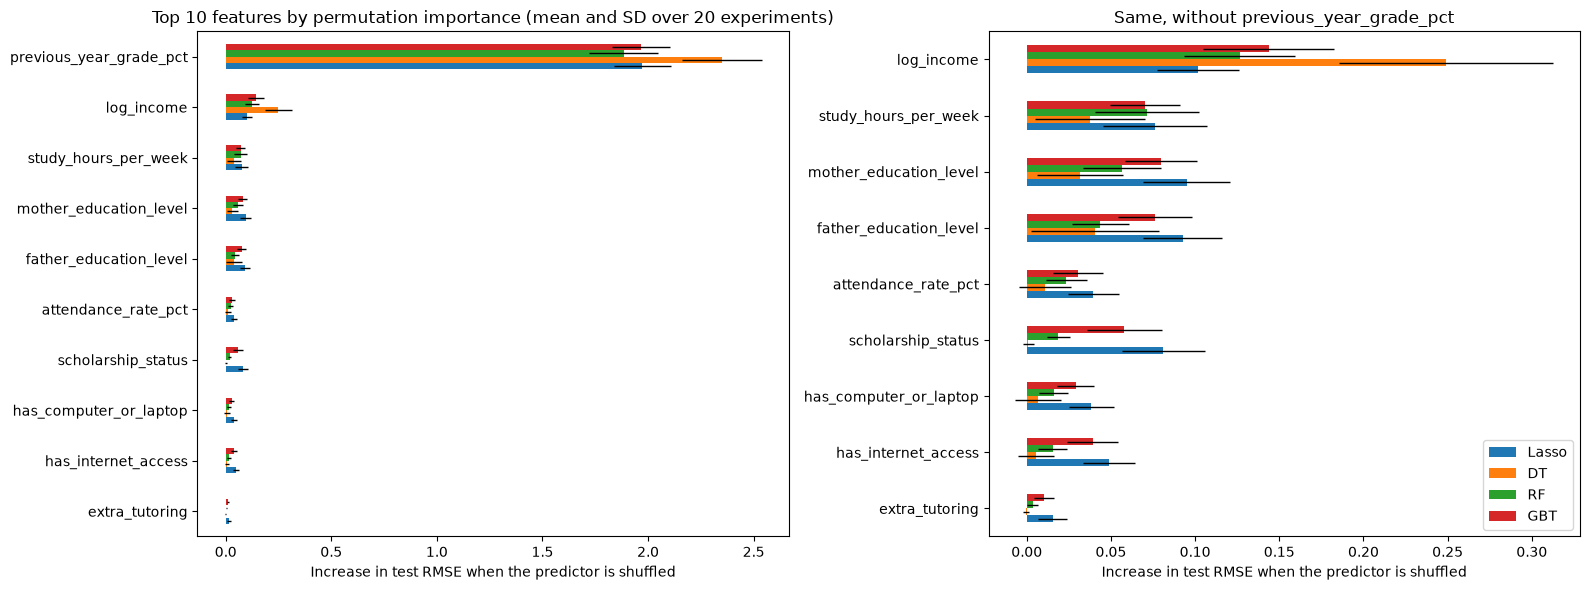

Share of the 20 experiments in which the Lasso kept each predictor:


,share of experiments
scholarship_status,1.00
attendance_rate_pct,1.00
previous_year_grade_pct,1.00
log_income,1.00
family_size,1.00
single_parent_household,1.00
has_internet_access,1.00
has_computer_or_laptop,1.00
extra_tutoring,1.00
study_hours_per_week,1.00


Lasso coefficients, 15 largest by size:


,mean coefficient,SD over experiments,share non-zero
num__previous_year_grade_pct,4.518,0.036,1.00
ordinal__scholarship_status,1.339,0.137,1.00
num__log_income,0.963,0.047,1.00
num__study_hours_per_week,0.821,0.067,1.00
num__has_internet_access,0.661,0.044,1.00
ordinal__mother_education_level,0.634,0.042,1.00
num__has_computer_or_laptop,0.614,0.051,1.00
num__attendance_rate_pct,0.611,0.067,1.00
ordinal__father_education_level,0.597,0.034,1.00
onehot__father_occupation_Unemployed,0.521,0.276,0.95


In [83]:
# Feature importance across the experiments
# The importances and the Lasso results were collected in the main script, so nothing is refitted here
from IPython.display import display

importance_by_experiment = pd.DataFrame(importance_records)       # one row per (experiment, model)
n_experiments = importance_by_experiment['experiment'].nunique()
model_order = ['Lasso', 'DT', 'RF', 'GBT']
grouped = importance_by_experiment.groupby('model')[PREDICTOR_COLS]
feature_importance_all = grouped.mean().T[model_order]            # mean importance over the experiments
feature_importance_sd = grouped.std().T[model_order]              # spread over the experiments

# Top 10 predictors by mean importance across the four models
top_features = feature_importance_all.mean(axis=1).nlargest(10).index
mean_plot = feature_importance_all.loc[top_features].sort_values('RF')
sd_plot = feature_importance_sd.loc[mean_plot.index]

# One predictor is far ahead of the rest, so the right panel drops it to show the other predictors
dominant_feature = mean_plot.mean(axis=1).idxmax()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mean_plot.plot.barh(ax=axes[0], xerr=sd_plot, error_kw={'elinewidth': 1}, legend=False)
axes[0].set_title(f'Top 10 features by permutation importance (mean and SD over {n_experiments} experiments)')
mean_plot.drop(index=dominant_feature).plot.barh(ax=axes[1], xerr=sd_plot.drop(index=dominant_feature), error_kw={'elinewidth': 1})
axes[1].set_title(f'Same, without {dominant_feature}')
for ax in axes:
    ax.set_xlabel('Increase in test RMSE when the predictor is shuffled')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

# How often the Lasso kept each predictor (a predictor is kept if any of its encoded columns is non-zero)
selection_frequency = pd.DataFrame(lasso_selection_records).drop(columns='experiment').mean().sort_values(ascending=False)
print(f'Share of the {n_experiments} experiments in which the Lasso kept each predictor:')
display(selection_frequency.round(2).to_frame('share of experiments'))

# Lasso weights. Numeric columns are standardised, so their coefficient is the change in the predicted grade per 1 SD.
# Ordinal columns are per level step, and one-hot columns are relative to the first category.
coefficients = pd.DataFrame(lasso_coefficient_records).drop(columns='experiment')
coefficient_summary = pd.DataFrame({'mean coefficient': coefficients.mean(),
                                    'SD over experiments': coefficients.std(),
                                    'share non-zero': (coefficients != 0).mean()})
coefficient_summary = coefficient_summary.reindex(coefficient_summary['mean coefficient'].abs().sort_values(ascending=False).index)
print('Lasso coefficients, 15 largest by size:')
display(coefficient_summary.head(15).round(3))